# Synthetic routing results — full grid

The full factorial contains 2,187 configurations and seven parent–child comparisons each. Distinct routing jobs are reused across configurations. This notebook inspects completed comparisons; it does not rerun routing. Change `EXPERIMENT` to `baseline` or `extremes` to inspect the smaller batches.

These are deterministic model responses, not independent field observations. Synthetic speed changes use modeled lags rather than observed gauge timing.

This version includes **nested/main_island_only**: collapse the main island while retaining the upper inner branch and its length adjustment. Results come from `full_grid_island`; the original six-comparison grid remains in `full_grid`.

**Current synthetic version · 30 September 2026:** BASED reference depth, local width–depth exponent **α=0.65**, Manning n=0.035, X=0.1 and 200m segmentation/floor. Responses and local-kb resistance are recomputed from the versioned routing run. Geometry and validation partitions are unchanged. **Real-case comparison is deferred until the updated-slope runs.** Earlier outputs are preserved separately; the old-versus-new comparison changes the complete hydraulic setup, not alpha alone.


In [1]:
from pathlib import Path
import sys, json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'synthetic_experiments'/'src').is_dir())
for p in (ROOT,ROOT/'synthetic_experiments'/'src',ROOT/'RAPID'/'src'):
    if str(p) not in sys.path: sys.path.insert(0,str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
EXPERIMENT='full_grid_island'
import sys
sys.path.insert(0,str(ROOT/'synthetic_experiments/investigations'))
from analysis_paths import results_root
ACTIVE_RUN=results_root()/'full_grid_island'
ACTIVE_EXTENSION=results_root()/'embedded_width_length_extension'
assert json.loads((ACTIVE_RUN/'manifest.json').read_text())['config']['selected_hydraulic_reference']['depth_alpha']==.65
OUTPUT=ACTIVE_RUN
if not (OUTPUT/'results.csv').exists():
    raise FileNotFoundError('Run the plan, run, and analyse commands in synthetic_experiments/RUNBOOK.md first')
results=pd.read_csv(OUTPUT/'results.csv')
manifest=json.loads((OUTPUT/'manifest.json').read_text())
display(pd.Series({k:v for k,v in manifest.items() if k.startswith('n_')},name='Plan'))
display(results[['configuration_id','child_state','Lambda_matched','lag_shift_pct',
                 'lag_shift_seconds','timing_resolution_seconds','parent_volume_error','child_volume_error']])
assert not results.duplicated(['configuration_id','child_state']).any()
assert np.isfinite(results[['Lambda_matched','resistance_predictor','lag_shift_pct']]).all().all()
assert (results.groupby('configuration_id').size()==7).all()
assert len(results)==manifest['n_comparisons']
BASELINE=dict(total_width_m=500,reference_slope=.0001,outer_a_fraction=.8,inner_fraction=.5,
              length_multiplier=1.,total_length_m=20000,internal_location='central')


n_configurations     2187
n_comparisons       15309
n_unique_runs        9519
Name: Plan, dtype: int64

,configuration_id,child_state,Lambda_matched,lag_shift_pct,lag_shift_seconds,timing_resolution_seconds,parent_volume_error,child_volume_error
0,a3d8f1017d03e3594dbfdf5c,simple/full,0.258816,-15.178571,-2074.0,122,5.748905e-15,-1.137006e-14
1,a3d8f1017d03e3594dbfdf5c,nested/inner_only,0.469530,-2.608696,-366.0,122,6.004412e-15,5.748905e-15
2,a3d8f1017d03e3594dbfdf5c,nested/main_island_only,0.258036,-13.913043,-1952.0,122,6.004412e-15,-5.365644e-15
3,a3d8f1017d03e3594dbfdf5c,nested/full,0.216665,-17.391304,-2440.0,122,6.004412e-15,-1.137006e-14
4,a3d8f1017d03e3594dbfdf5c,crossover/upstream_only,0.672299,-5.217391,-732.0,122,4.471370e-15,-4.471370e-15
...,...,...,...,...,...,...,...,...
15304,b41a83943be03b1776be71c8,nested/main_island_only,0.797324,-3.601695,-1020.0,60,1.034803e-14,1.060354e-14
15305,b41a83943be03b1776be71c8,nested/full,0.370529,-20.127119,-5700.0,60,1.034803e-14,1.609693e-14
15306,b41a83943be03b1776be71c8,crossover/upstream_only,0.566158,-17.598344,-5100.0,60,1.596918e-14,3.334365e-14
15307,b41a83943be03b1776be71c8,crossover/downstream_only,0.491528,-19.461698,-5640.0,60,1.596918e-14,1.430839e-14


## Completion and response signs

Summaries count comparison rows; some share the same routing jobs. A positive lag shift means the child peak arrives later. The within-step flag is a screening aid, not a confidence interval.

In [2]:
summary=results.groupby('child_state').agg(
    comparisons=('lag_shift_pct','size'),min_lag_pct=('lag_shift_pct','min'),
    median_lag_pct=('lag_shift_pct','median'),max_lag_pct=('lag_shift_pct','max'),
    later_peaks=('lag_shift_pct',lambda s:int((s>0).sum())),
    unchanged_peaks=('lag_shift_pct',lambda s:int((s==0).sum())))
display(summary)
within_step=results.lag_shift_seconds.abs()<=results.timing_resolution_seconds
print(f'{within_step.sum()} comparisons have an absolute lag change no larger than one routing timestep.')
print(f'{((results.parent_capped_segments>0)|(results.child_capped_segments>0)).sum()} comparisons involve an active celerity cap.')


0 comparisons have an absolute lag change no larger than one routing timestep.
0 comparisons involve an active celerity cap.


,comparisons,min_lag_pct,median_lag_pct,max_lag_pct,later_peaks,unchanged_peaks
child_state,,,,,,
crossover/downstream_only,2187,-23.517787,-12.025316,-2.654867,0,0
crossover/full,2187,-26.757812,-18.644068,-10.262530,0,0
crossover/upstream_only,2187,-24.708171,-10.666667,-0.934579,0,0
nested/full,2187,-27.325581,-18.103448,-8.958838,0,0
nested/inner_only,2187,-20.231214,-8.256881,-2.162162,0,0
nested/main_island_only,2187,-23.333333,-10.000000,-2.905569,0,0
simple/full,2187,-39.685658,-23.684211,-3.341902,0,0


## Primary resistance–timing result

X = length fraction × exposure × −log10(resistance ratio). Negative lag change means an earlier outlet peak relative to the prescribed inlet pulse. Every child is compared with its corresponding original. The static overview preserves signs. Exported interactive signed/logarithmic figures and filter legends are under the experiment's `figures/` directory.

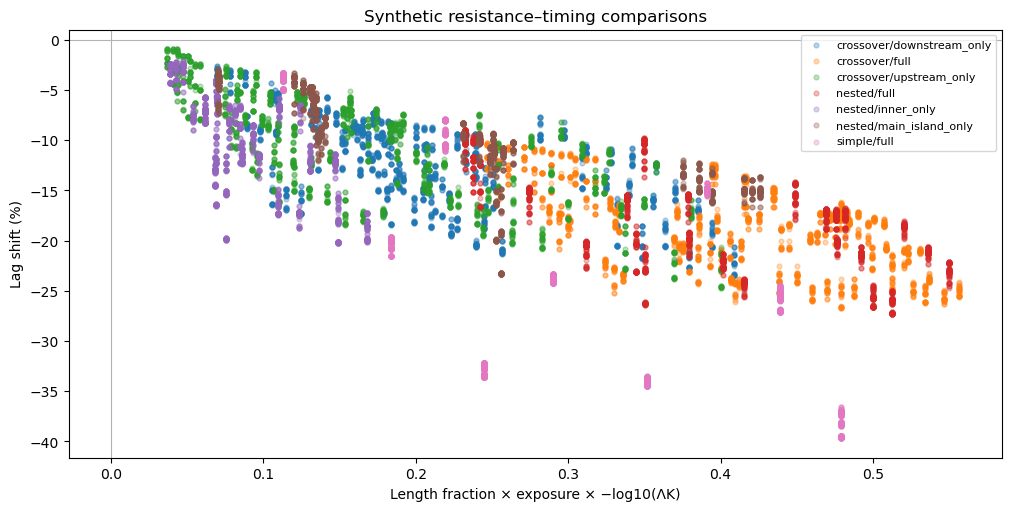

In [3]:
fig,ax=plt.subplots(figsize=(10,5),constrained_layout=True)
for label,part in results.groupby('child_state'):
    ax.scatter(part.resistance_predictor,part.lag_shift_pct,label=label,s=12,alpha=.3)
ax.axhline(0,color='0.7',lw=.8); ax.axvline(0,color='0.7',lw=.8)
ax.set(xlabel='Length fraction × exposure × −log10(ΛK)',ylabel='Lag shift (%)',
       title='Synthetic resistance–timing comparisons')
ax.legend(loc='best',fontsize=8)
display(fig); plt.close(fig)

## One-factor slices through the baseline

Each panel varies only the labelled factor and holds all others at their baseline values. Lines connect the three tested levels; they do not imply continuous sampling. Location translates the internal feature, so the simple case is unchanged. Individual grid configurations use coordinated timesteps; timestep and safeguard diagnostics remain part of interpretation.

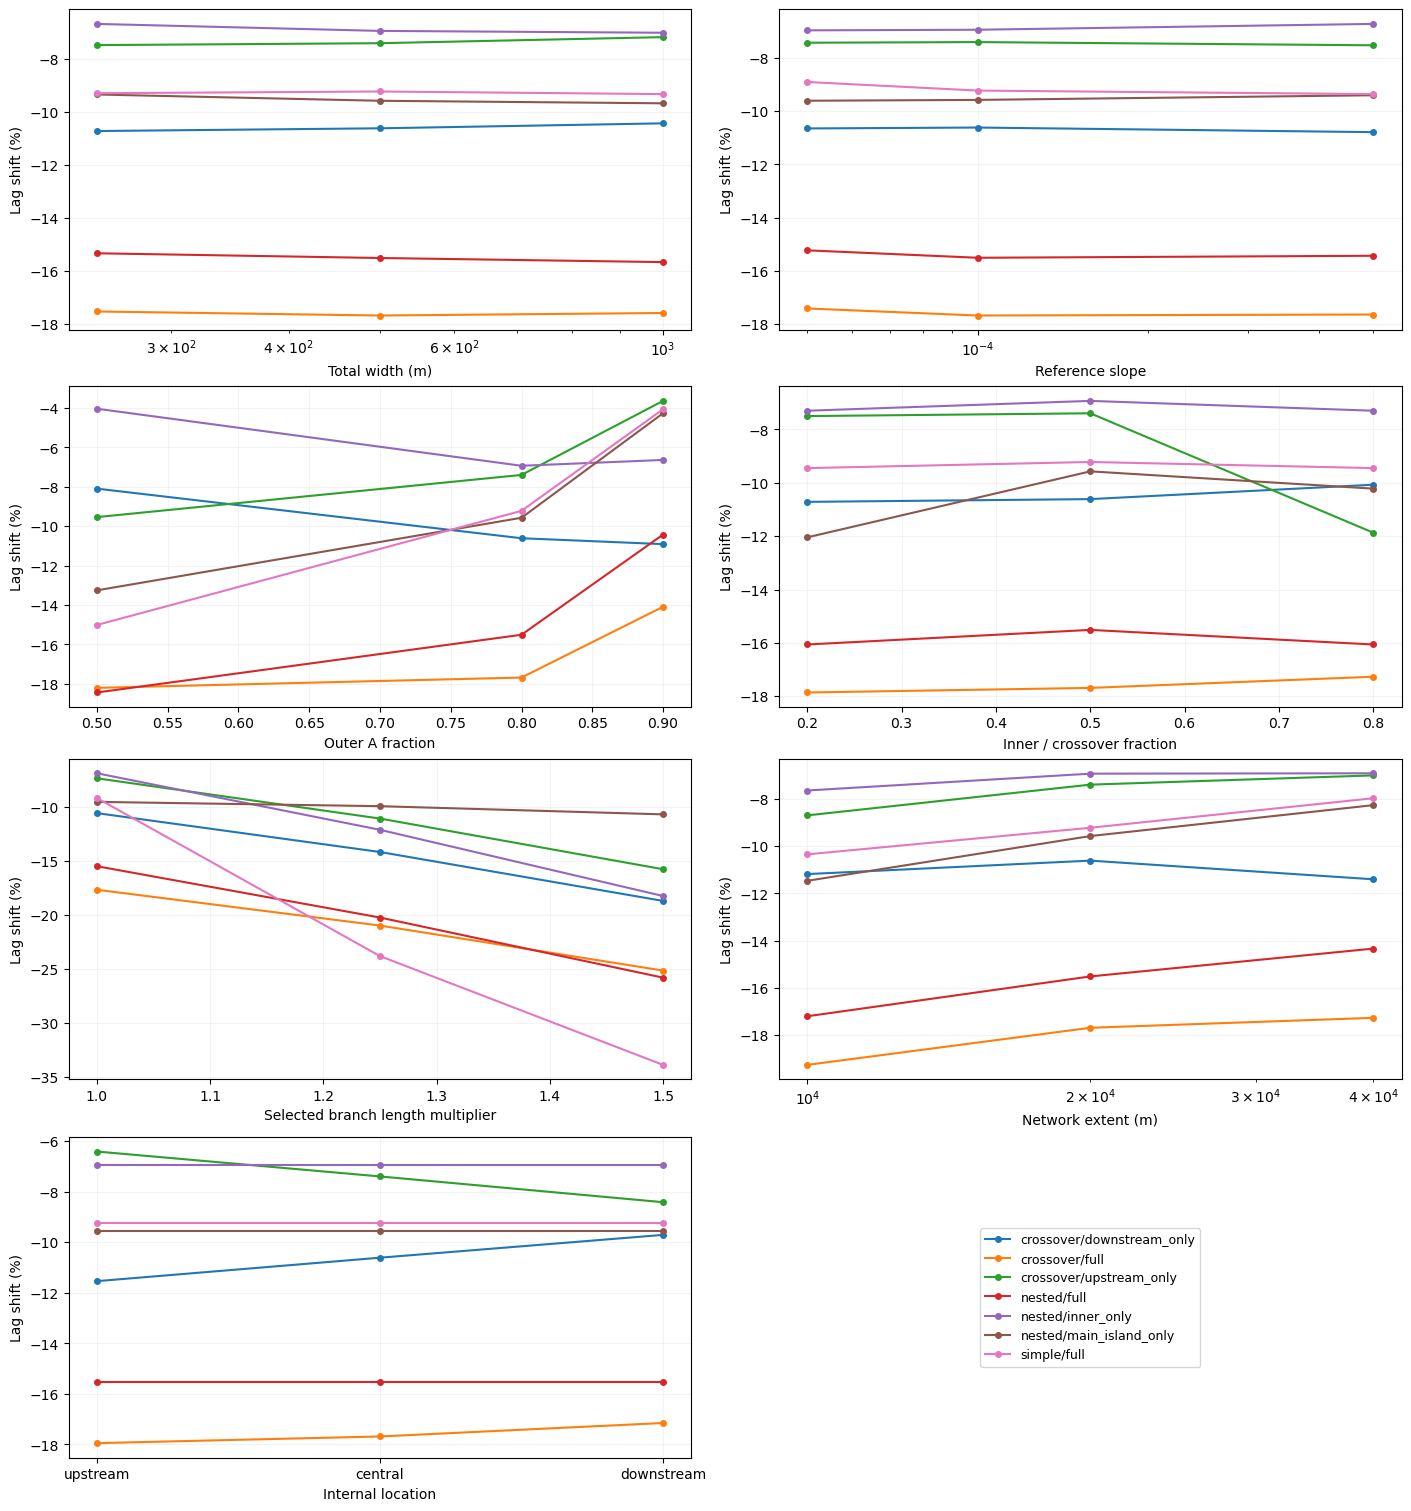

In [4]:
fig,axes=plt.subplots(4,2,figsize=(14,15),constrained_layout=True)
labels={"total_width_m":"Total width (m)","reference_slope":"Reference slope",
        "outer_a_fraction":"Outer A fraction","inner_fraction":"Inner / crossover fraction",
        "length_multiplier":"Selected branch length multiplier","total_length_m":"Network extent (m)",
        "internal_location":"Internal location"}
for ax,factor in zip(axes.flat,BASELINE):
    mask=pd.Series(True,index=results.index)
    for other,value in BASELINE.items():
        if other!=factor: mask &= results[other].eq(value)
    subset=results.loc[mask]
    for state,part in subset.groupby('child_state'):
        if factor=='internal_location':
            part=part.assign(_order=part[factor].map({'upstream':0,'central':1,'downstream':2})).sort_values('_order')
        else: part=part.sort_values(factor)
        ax.plot(part[factor],part.lag_shift_pct,'o-',label=state,markersize=4)
    ax.set(xlabel=labels[factor],ylabel='Lag shift (%)')
    if factor in ('total_width_m','reference_slope','total_length_m'): ax.set_xscale('log')
    ax.grid(alpha=.15)
handles,labels_=axes.flat[0].get_legend_handles_labels()
axes.flat[-1].axis('off'); axes.flat[-1].legend(handles,labels_,loc='center',fontsize=9)
display(fig); plt.close(fig)


## Later peaks despite reduced resistance

These cases demonstrate that the resistance ratio alone does not determine the sign of the modeled peak-time response. They warrant inspection of paired hydrographs, changed flow allocation, and resolution sensitivity before assigning a mechanism. The table lists the largest later-peak responses, not a random sample.

In [5]:
later=results.loc[(results.lag_shift_pct>0)&(results.Lambda_matched<1)].copy()
later['lag_change_in_timesteps']=later.lag_shift_seconds/later.timing_resolution_seconds
print(f'{len(later)} later-peak comparisons with resistance reduction; '
      f'{(later.lag_change_in_timesteps>1).sum()} exceed one timestep.')
display(later.sort_values('lag_shift_pct',ascending=False)[
    ['configuration_id','child_state',*BASELINE,'Lambda_matched','lag_shift_pct',
     'lag_change_in_timesteps','parent_capped_segments','child_capped_segments']].head(12))


0 later-peak comparisons with resistance reduction; 0 exceed one timestep.


,configuration_id,child_state,total_width_m,reference_slope,outer_a_fraction,inner_fraction,length_multiplier,total_length_m,internal_location,Lambda_matched,lag_shift_pct,lag_change_in_timesteps,parent_capped_segments,child_capped_segments


## Paired hydrographs

Show one configuration at a time. Time zero is the start of the inlet pulse after initialization. Both parent and child use identical forcing and numerical schedules.

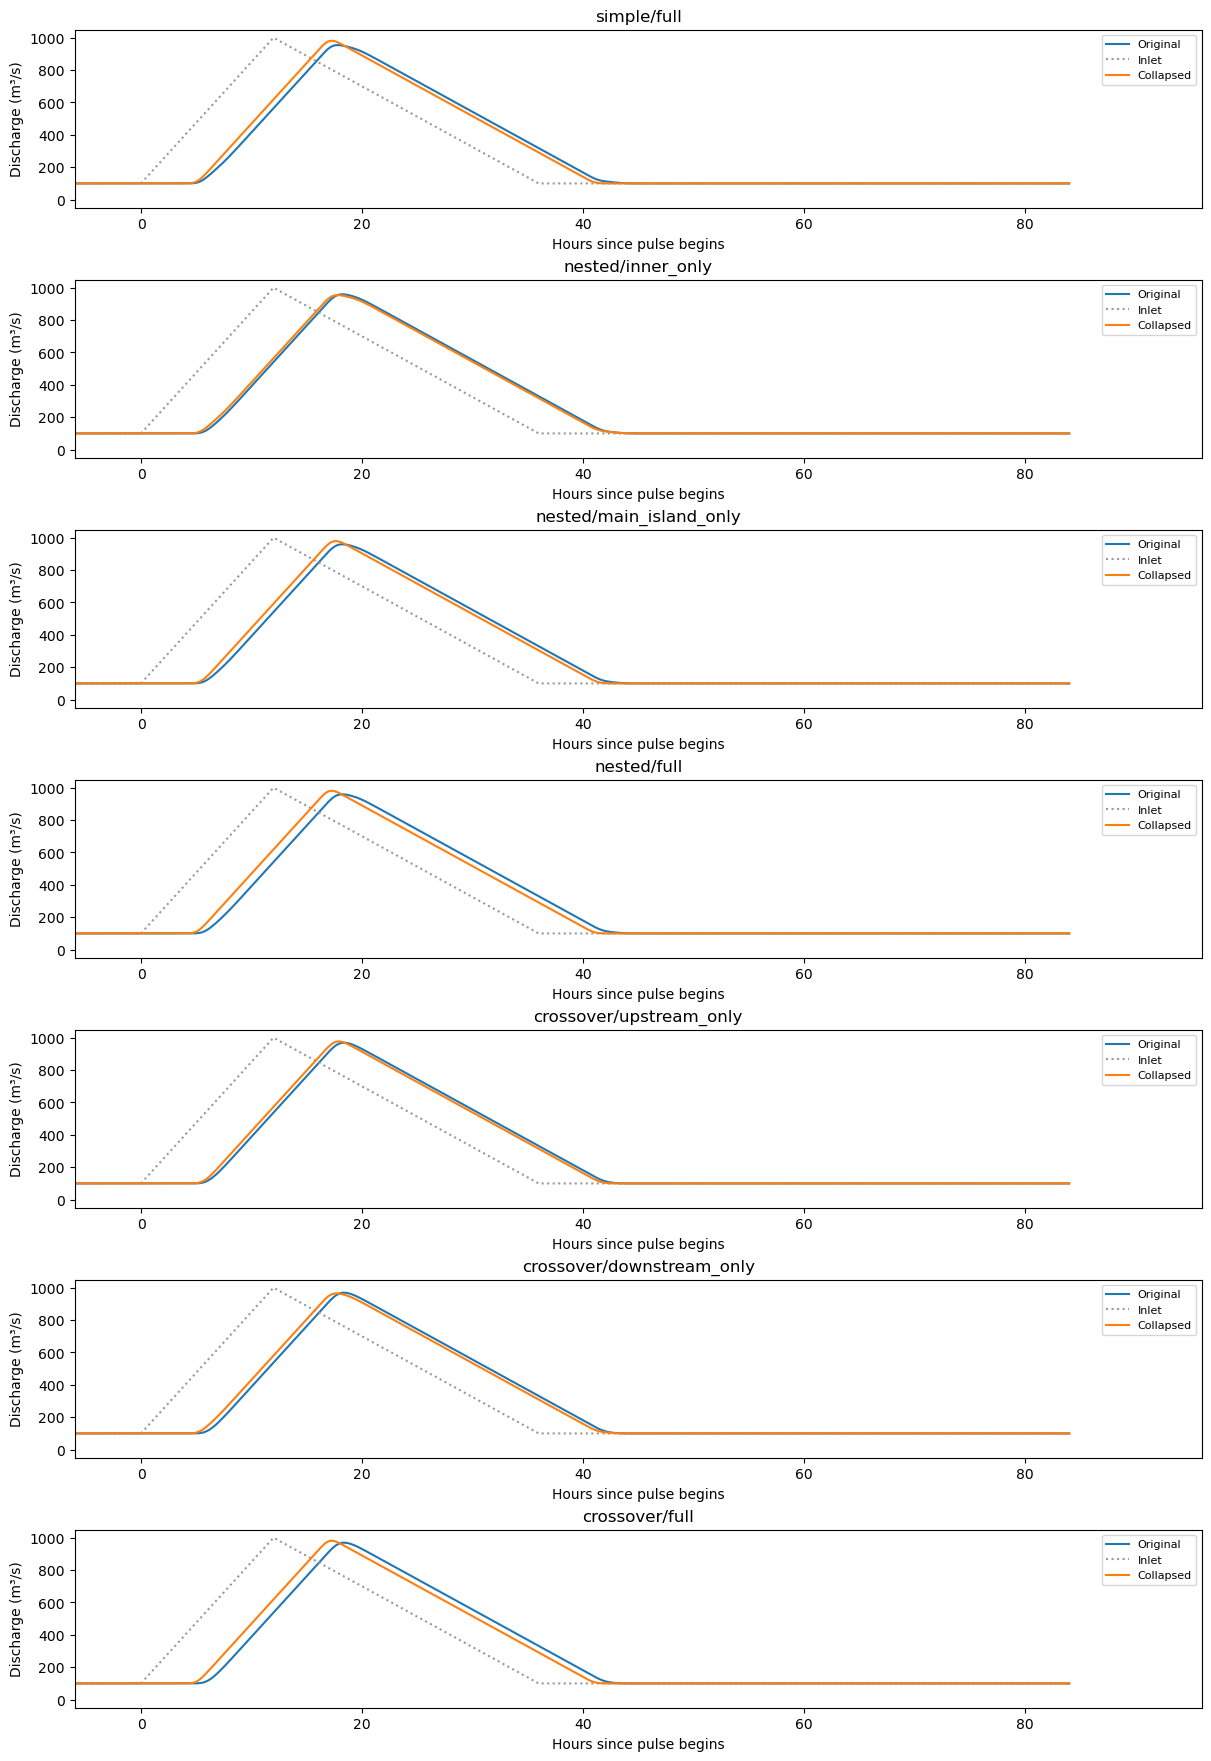

In [6]:
baseline_mask=pd.Series(True,index=results.index)
for key,value in BASELINE.items(): baseline_mask &= results[key].eq(value)
CONFIGURATION_ID=(results.loc[baseline_mask,'configuration_id'].iloc[0]
                  if baseline_mask.any() else results.configuration_id.iloc[0])
selected=results.loc[results.configuration_id.eq(CONFIGURATION_ID)]
fig,axes=plt.subplots(len(selected),1,figsize=(12,2.5*len(selected)),squeeze=False,constrained_layout=True)
for ax,row in zip(axes[:,0],selected.itertuples()):
    for field,label in [('parent_run_id','Original'),('child_run_id','Collapsed')]:
        folder=OUTPUT/'runs'/getattr(row,field)
        hydro=pd.read_parquet(folder/'hydrograph.parquet')
        metrics=json.loads((folder/'metrics.json').read_text())
        hours=hydro.time_seconds/3600-metrics['buffer_hours']
        ax.plot(hours,hydro.outlet_cms,label=label)
        if field=='parent_run_id': ax.plot(hours,hydro.inlet_cms,':',color='0.6',label='Inlet')
    ax.set(title=row.child_state,xlabel='Hours since pulse begins',ylabel='Discharge (m³/s)',xlim=(-6,96))
    ax.legend(fontsize=8)
display(fig); plt.close(fig)

## Resolution and initialization checks

The following matched numerical audit is rerun using the selected reference. It covers seven nested/full configurations and tests segmentation/floor, timestep, X and pulse duration. It does not establish convergence across every geometry.

In [7]:
numerical=pd.read_csv(OUTPUT/'current_analysis/omega_numerical_check.csv')
display(numerical[['case','variant','lag_shift_pct','event_duration_change_pct','peak_excess_change_pct','n_capped','n_floored']])

,case,variant,lag_shift_pct,event_duration_change_pct,peak_excess_change_pct,n_capped,n_floored
0,baseline,baseline_200m,-20.249221,-2.356913,2.362526,0,0
1,baseline,refined_100m,-20.000000,-2.306778,2.576860,0,0
2,baseline,refined_50m,-19.755102,-2.285871,2.778638,0,0
3,baseline,larger_stable_dt,-20.625000,-2.353398,2.365588,0,0
4,baseline,muskingum_X_0.2,-20.754717,-2.326917,2.448247,0,0
5,baseline,double_pulse_duration,-20.249221,-0.752769,1.155051,0,0
6,total_width_m=250,baseline_200m,-20.125786,-1.950374,2.077436,0,0
7,total_width_m=250,refined_100m,-20.031797,-1.881615,2.266919,0,0
8,total_width_m=250,refined_50m,-19.834711,-1.836648,2.445068,0,0
9,total_width_m=250,larger_stable_dt,-20.754717,-1.947770,2.078988,0,0


## Optional shared interactive plots

The plotting helper below is the same one used by the real-network analysis. Uncomment the final line in a trusted notebook for interactive sign/category filters.

In [8]:
from rapid_tools.response_diagnostics import make_signed_magnitude_scatter, show_signed_scatter
interactive=make_signed_magnitude_scatter(results,x='resistance_predictor',y='lag_shift_pct',
    log_x=True,log_y=True,response_name='Lag',title='Synthetic resistance–timing: log magnitudes')
show_signed_scatter(interactive)